In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shutil , os 
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense , Activation , GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator , load_img , img_to_array
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping , ReduceLROnPlateau , ModelCheckpoint
from tensorflow.keras.applications import EfficientNetB2
from tensorflow.keras.metrics import categorical_crossentropy
from sklearn.metrics import confusion_matrix , classification_report

In [3]:
train_dir = 'Dataset/train/'
valid_dir = 'Dataset/valid/'
test_dir = 'Dataset/test/'

### class_mode='sparse' : will convert labels into 0 ... 9 automatically

In [4]:

train_batches = ImageDataGenerator( rotation_range= 10 , zoom_range= 0.1 , 
                                     width_shift_range = 0.1 , height_shift_range=0.1

                                    ).flow_from_directory(
                                        train_dir , 
                                        target_size = ( 260 , 260 ) ,
                                        batch_size = 32 , 
                                        class_mode='sparse' , 
                                        shuffle = True
                                     )

Found 1493 images belonging to 10 classes.


In [5]:
valid_batches = ImageDataGenerator(
).flow_from_directory( valid_dir , target_size = (260 , 260) , 
                      batch_size = 32 , class_mode = 'sparse' , shuffle=False 
                     )

test_batches = ImageDataGenerator(
).flow_from_directory( test_dir , target_size=( 260 , 260 ), batch_size= 32 ,
                      class_mode= 'sparse' , shuffle=False
                     )

Found 409 images belonging to 10 classes.
Found 160 images belonging to 10 classes.


In [6]:
base_model = EfficientNetB2( weights='imagenet' , 
                            include_top=False , input_shape=( 260 , 260 , 3 ))

for layer in base_model.layers[ : -30 ] :
    layer.trainable = False


for layer in base_model.layers[ -30 : ]:
    layer.trainable = True

In [7]:
x = GlobalAveragePooling2D()( base_model.output )

x = Dense( 128 , activation='relu')( x )
x = Dropout( 0.3 )( x )

x = Dense( 64 , activation='relu')( x )
x = Dropout( 0.2 )( x )

output = Dense( 10 , activation='softmax')(x)

model = Model( inputs = base_model.input , outputs = output )

# model.summary()

 - Total params: 7,957,827 (30.36 MB)
 - Trainable params: 3,163,926 (12.07 MB)
 - Non-trainable params: 4,793,901 (18.29 MB)

In [8]:
model.compile( optimizer=Adam(learning_rate=1e-5) ,
               loss='sparse_categorical_crossentropy' , metrics=['accuracy'])

In [9]:
early_stop = EarlyStopping( monitor='val_loss' , patience= 10 ,
                       verbose= 0 , mode='auto', restore_best_weights=True )
 
reduce_lr = ReduceLROnPlateau( monitor='val_loss' , patience= 5 , 
                              factor= 0.1 , min_lr= 0.0000001 )

model_check_point = ModelCheckpoint( 'digits_best_model.keras' , 
                                    monitor='val_loss' , save_best_only=True )

callbacks = [ early_stop , reduce_lr , model_check_point ]

In [10]:
fit_history = model.fit( train_batches , epochs= 60 ,
                         validation_data= valid_batches , batch_size= 32 ,
                          verbose= 1 , callbacks= callbacks )

Epoch 1/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 141s 3s/step - accuracy: 0.1179 - loss: 2.3414 - val_accuracy: 0.1027 - val_loss: 2.2832 - learning_rate: 1.0000e-05
Epoch 2/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.1561 - loss: 2.2591 - val_accuracy: 0.1858 - val_loss: 2.1950 - learning_rate: 1.0000e-05
Epoch 3/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.1815 - loss: 2.2119 - val_accuracy: 0.3203 - val_loss: 2.1078 - learning_rate: 1.0000e-05
Epoch 4/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 112s 2s/step - accuracy: 0.2391 - loss: 2.1633 - val_accuracy: 0.4156 - val_loss: 2.0220 - learning_rate: 1.0000e-05
Epoch 5/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.2800 - loss: 2.0974 - val_accuracy: 0.4963 - val_loss: 1.9313 - learning_rate: 1.0000e-05
Epoch 6/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.3369 - loss: 2.0346 - val_accuracy: 0.5232 - val_loss: 1.8328 - learning_rate: 1.0000e-05
Epoch 7/60
47/47 ━━━━━━━━━━━━━━━━━━━━ 113s 2s/step - accuracy: 0.3798 

In [11]:
acc = fit_history.history['accuracy'] 
loss = fit_history.history['loss'] 
val_acc = fit_history.history['val_accuracy'] 
val_loss = fit_history.history['val_loss'] 
 
epochs = np.arange( 0 , len( acc ) )

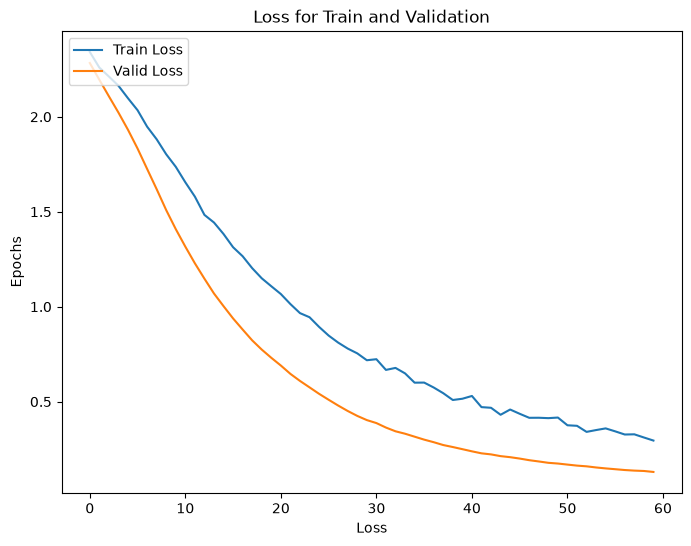

In [12]:
plt.figure(figsize=( 8 , 6 ))

plt.plot( epochs , loss , label = 'Train Loss')
plt.plot( epochs , val_loss , label = 'Valid Loss')

plt.legend(loc='upper left')
plt.title('Loss for Train and Validation')
plt.xlabel('Loss')
plt.ylabel('Epochs')

plt.show()


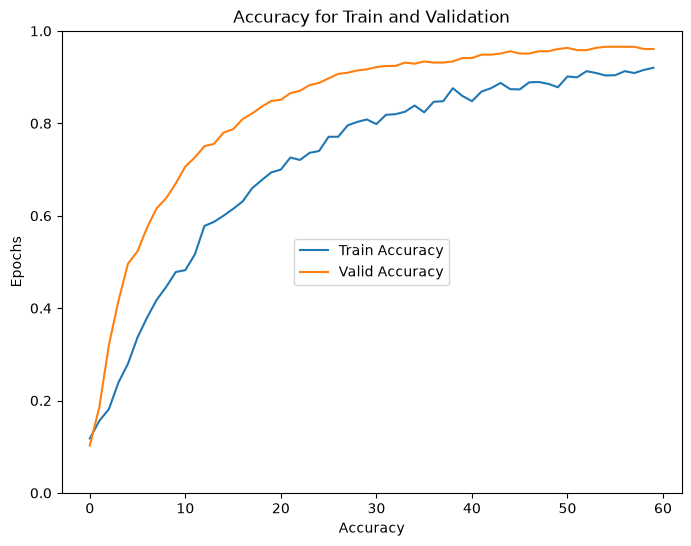

In [13]:
plt.figure(figsize=( 8 , 6 ))

plt.plot( epochs , acc , label = 'Train Accuracy')
plt.plot( epochs , val_acc , label = 'Valid Accuracy')

plt.legend(loc='center')
plt.title('Accuracy for Train and Validation')
plt.xlabel('Accuracy')
plt.ylabel('Epochs')
plt.ylim([0 , 1 ])

plt.show()

In [14]:
test_batches.reset()
test_labels = test_batches.classes
test_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4,
       4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9,
       9, 9, 9, 9, 9, 9], dtype=int32)

In [15]:
y_pred_proba = model.predict( test_batches , batch_size= len( test_batches) , verbose= 0)
y_pred_proba[ : 5 ]

array([[9.95612144e-01, 2.15034862e-03, 3.78769182e-04, 1.14911280e-04,
        3.97926669e-06, 2.23771767e-05, 2.06575729e-04, 8.71984084e-05,
        1.39115809e-03, 3.24357134e-05],
       [9.93015289e-01, 2.75578676e-03, 6.86514366e-04, 5.26357850e-04,
        2.04684929e-05, 1.17892996e-04, 7.50687905e-04, 3.23827087e-04,
        1.55747181e-03, 2.45642412e-04],
       [9.95243847e-01, 3.20746168e-03, 2.15443244e-04, 8.61275475e-05,
        1.51451036e-06, 6.41358638e-05, 2.21657683e-04, 3.16397163e-05,
        5.35426952e-04, 3.92702263e-04],
       [9.92380679e-01, 2.11942475e-03, 7.20448152e-04, 6.46853994e-04,
        2.23528641e-05, 1.31756358e-04, 8.58819403e-04, 5.58837550e-04,
        2.33600428e-03, 2.24738978e-04],
       [9.99456227e-01, 1.56565875e-04, 4.02027727e-05, 3.02879489e-05,
        3.41807436e-07, 2.80941890e-06, 6.62238890e-05, 1.07323222e-05,
        2.30516031e-04, 6.11836549e-06]], dtype=float32)

In [16]:
y_pred = y_pred_proba.argmax( axis=1 )
print(f"predictions = {y_pred[ : 30 ]}")
print(f"     Actual = {test_labels[ : 30 ]}")


predictions = [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
     Actual = [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


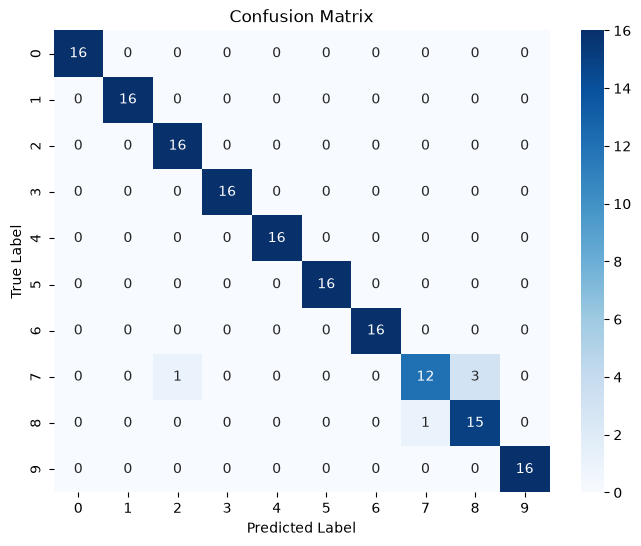

In [17]:
cm = confusion_matrix( test_labels , y_pred  )

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [18]:
print( classification_report( test_labels , y_pred ))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        16
           1       1.00      1.00      1.00        16
           2       0.94      1.00      0.97        16
           3       1.00      1.00      1.00        16
           4       1.00      1.00      1.00        16
           5       1.00      1.00      1.00        16
           6       1.00      1.00      1.00        16
           7       0.92      0.75      0.83        16
           8       0.83      0.94      0.88        16
           9       1.00      1.00      1.00        16

    accuracy                           0.97       160
   macro avg       0.97      0.97      0.97       160
weighted avg       0.97      0.97      0.97       160

